# AIML Lab Exercise 6: Build an Artificial Neural Network using the Backpropagation Algorithm
**Datasets:** XOR truth table and Iris Flower Dataset (iris.csv)

This notebook builds a **feed-forward neural network from scratch using only NumPy**. The network is trained with the **backpropagation** algorithm and gradient descent, and is tested on two datasets:
1. The **XOR problem**, which a single perceptron cannot solve because it is not linearly separable.
2. The **Iris dataset**, a 3-class classification problem with 4 numeric features.

## 1. Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neural_network import MLPClassifier

np.random.seed(42)
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Activation functions and their derivatives
An artificial neuron computes a weighted sum of its inputs plus a bias, and passes it through an **activation function** to introduce non-linearity:

$$a = f\left(\sum_i w_i x_i + b\right)$$

| Function | Formula | Derivative |
|---|---|---|
| Sigmoid | σ(z) = 1 / (1 + e⁻ᶻ) | σ(z)(1 − σ(z)) |
| Tanh | tanh(z) | 1 − tanh²(z) |
| ReLU | max(0, z) | 1 if z > 0 else 0 |
| Softmax (output layer) | eᶻⁱ / Σⱼ eᶻʲ | used together with cross-entropy |

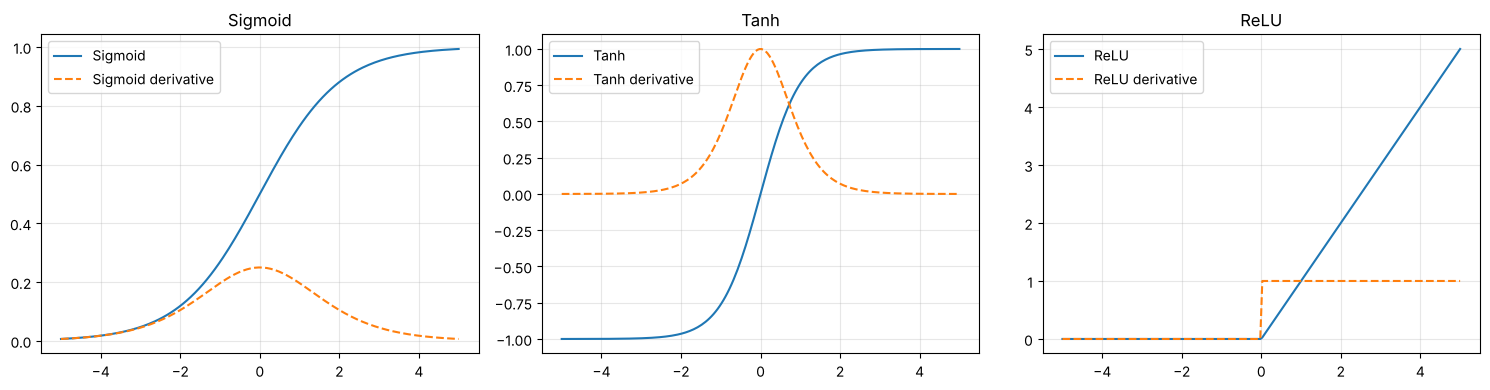

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # takes the activation a = sigmoid(z) and returns d(sigmoid)/dz
    return a * (1 - a)

def tanh_derivative(a):
    return 1 - a ** 2

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    exp_z = np.exp(z - z.max(axis=1, keepdims=True))   # subtract max for numerical stability
    return exp_z / exp_z.sum(axis=1, keepdims=True)

z = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, f, df) in zip(axes, [
        ('Sigmoid', sigmoid(z), sigmoid_derivative(sigmoid(z))),
        ('Tanh', np.tanh(z), tanh_derivative(np.tanh(z))),
        ('ReLU', relu(z), (z > 0).astype(float))]):
    ax.plot(z, f, label=name)
    ax.plot(z, df, '--', label=f"{name} derivative")
    ax.set_title(name)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Build the neural network class with forward propagation and backpropagation
**Architecture:** input layer → hidden layer (sigmoid) → output layer (softmax)

**Forward propagation**

$$Z_1 = XW_1 + b_1,\quad A_1 = \sigma(Z_1),\quad Z_2 = A_1W_2 + b_2,\quad \hat{Y} = \text{softmax}(Z_2)$$

**Loss (categorical cross-entropy)**

$$L = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k} Y_{ik}\log\hat{Y}_{ik}$$

**Backpropagation** — the error is propagated backwards using the chain rule:

$$\delta_2 = \hat{Y} - Y,\qquad dW_2 = \frac{1}{m}A_1^T\delta_2,\qquad db_2 = \frac{1}{m}\sum\delta_2$$

$$\delta_1 = (\delta_2 W_2^T)\odot\sigma'(Z_1),\qquad dW_1 = \frac{1}{m}X^T\delta_1,\qquad db_1 = \frac{1}{m}\sum\delta_1$$

**Gradient descent update:** W := W − η·dW, b := b − η·db, where η is the learning rate.

In [3]:
class NeuralNetwork:
    def __init__(self, n_input, n_hidden, n_output, learning_rate=0.5, seed=42):
        rng = np.random.default_rng(seed)
        # Xavier initialisation keeps the activations in a good range
        self.W1 = rng.normal(0, np.sqrt(1 / n_input), (n_input, n_hidden))
        self.b1 = np.zeros((1, n_hidden))
        self.W2 = rng.normal(0, np.sqrt(1 / n_hidden), (n_hidden, n_output))
        self.b2 = np.zeros((1, n_output))
        self.lr = learning_rate

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = sigmoid(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = softmax(self.Z2)
        return self.A2

    def compute_loss(self, Y, Y_hat):
        return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

    def backward(self, X, Y):
        m = X.shape[0]
        delta2 = self.A2 - Y                                       # output layer error
        dW2 = self.A1.T @ delta2 / m
        db2 = delta2.sum(axis=0, keepdims=True) / m
        delta1 = (delta2 @ self.W2.T) * sigmoid_derivative(self.A1)  # hidden layer error
        dW1 = X.T @ delta1 / m
        db1 = delta1.sum(axis=0, keepdims=True) / m
        return dW1, db1, dW2, db2

    def update(self, grads):
        dW1, db1, dW2, db2 = grads
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def train(self, X, Y, epochs=1000, X_val=None, Y_val=None, verbose_every=0):
        self.history = {'loss': [], 'acc': [], 'val_loss': [], 'val_acc': []}
        for epoch in range(1, epochs + 1):
            Y_hat = self.forward(X)
            self.update(self.backward(X, Y))
            self.history['loss'].append(self.compute_loss(Y, Y_hat))
            self.history['acc'].append(np.mean(Y_hat.argmax(1) == Y.argmax(1)))
            if X_val is not None:
                val_hat = self.forward(X_val)
                self.history['val_loss'].append(self.compute_loss(Y_val, val_hat))
                self.history['val_acc'].append(np.mean(val_hat.argmax(1) == Y_val.argmax(1)))
            if verbose_every and epoch % verbose_every == 0:
                print(f"Epoch {epoch:5d} | loss = {self.history['loss'][-1]:.4f} | accuracy = {self.history['acc'][-1]:.4f}")
        return self

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

print("NeuralNetwork class defined.")

NeuralNetwork class defined.


## 4. Verify backpropagation using numerical gradient checking
To make sure the backpropagation formulas are correct, we compare the analytical gradient with a numerical estimate:

$$\frac{\partial L}{\partial w} \approx \frac{L(w + \epsilon) - L(w - \epsilon)}{2\epsilon}$$

A relative difference smaller than about 1e-7 means the implementation is correct.

In [4]:
rng = np.random.default_rng(0)
X_chk = rng.normal(size=(5, 4))
Y_chk = np.eye(3)[rng.integers(0, 3, 5)]
net_chk = NeuralNetwork(4, 5, 3)

net_chk.forward(X_chk)
analytic = net_chk.backward(X_chk, Y_chk)

def numerical_gradient(param, eps=1e-5):
    grad = np.zeros_like(param)
    for idx in np.ndindex(param.shape):
        original = param[idx]
        param[idx] = original + eps
        loss_plus = net_chk.compute_loss(Y_chk, net_chk.forward(X_chk))
        param[idx] = original - eps
        loss_minus = net_chk.compute_loss(Y_chk, net_chk.forward(X_chk))
        param[idx] = original
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

for name, param, a in zip(['W1', 'b1', 'W2', 'b2'],
                          [net_chk.W1, net_chk.b1, net_chk.W2, net_chk.b2], analytic):
    n = numerical_gradient(param)
    rel_diff = np.linalg.norm(a - n) / (np.linalg.norm(a) + np.linalg.norm(n))
    print(f"{name}: relative difference = {rel_diff:.2e}")

W1: relative difference = 3.11e-10
b1: relative difference = 1.33e-10
W2: relative difference = 1.42e-11
b2: relative difference = 1.76e-11


---
## 5. Test 1: Train the network on the XOR problem
| x₁ | x₂ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

XOR is **not linearly separable**, so it needs a hidden layer. The output is one-hot encoded into 2 classes.

In [5]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
Y_xor = np.eye(2)[y_xor]

xor_net = NeuralNetwork(n_input=2, n_hidden=4, n_output=2, learning_rate=1.0, seed=1)
xor_net.train(X_xor, Y_xor, epochs=5000, verbose_every=1000)

xor_probs = xor_net.predict_proba(X_xor)
display(pd.DataFrame({'x1': X_xor[:, 0], 'x2': X_xor[:, 1], 'Expected': y_xor,
                      'P(output = 1)': xor_probs[:, 1].round(4), 'Predicted': xor_net.predict(X_xor)}))
print("XOR accuracy:", accuracy_score(y_xor, xor_net.predict(X_xor)))

Epoch  1000 | loss = 0.0062 | accuracy = 1.0000
Epoch  2000 | loss = 0.0023 | accuracy = 1.0000


Epoch  3000 | loss = 0.0014 | accuracy = 1.0000
Epoch  4000 | loss = 0.0010 | accuracy = 1.0000
Epoch  5000 | loss = 0.0008 | accuracy = 1.0000


,x1,x2,Expected,P(output = 1),Predicted
0,0,0,0,0.0003,0
1,0,1,1,0.9991,1
2,1,0,1,0.9993,1
3,1,1,0,0.0013,0


XOR accuracy: 1.0


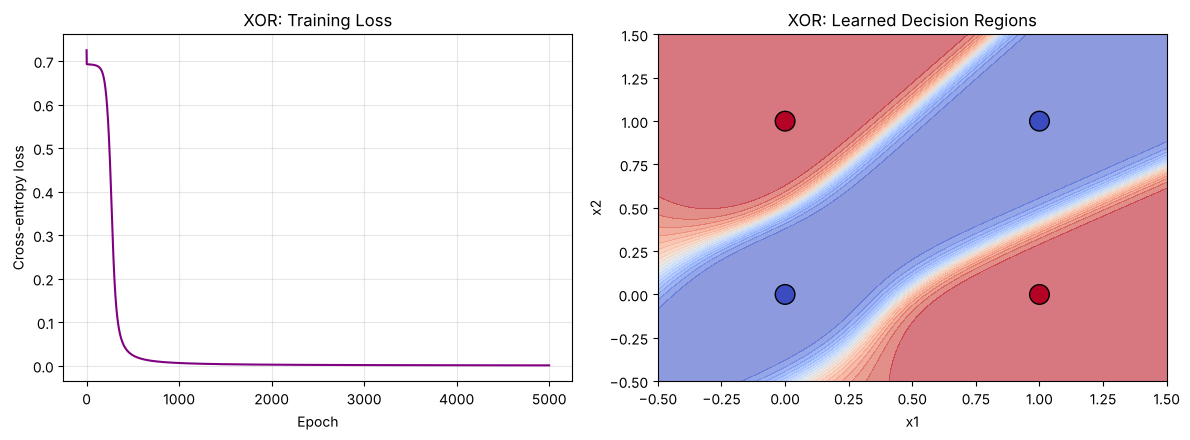

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(xor_net.history['loss'], color='purple')
axes[0].set_title('XOR: Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(alpha=0.3)

xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
probs = xor_net.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
axes[1].contourf(xx, yy, probs, levels=20, cmap='coolwarm', alpha=0.6)
axes[1].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap='coolwarm', s=200, edgecolors='black')
axes[1].set_title('XOR: Learned Decision Regions')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')
plt.tight_layout()
plt.show()

**Interpretation:** The network learns a non-linear decision region that puts (0,1) and (1,0) in one class and (0,0) and (1,1) in the other — something a single-layer perceptron cannot do.

---
## 6. Test 2: Load the Iris dataset

In [7]:
iris = pd.read_csv('iris.csv')
print("Dataset loaded successfully! Shape:", iris.shape)
iris.info()
display(iris.head())
print("\nClass distribution:\n", iris['species'].value_counts())

Dataset loaded successfully! Shape: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


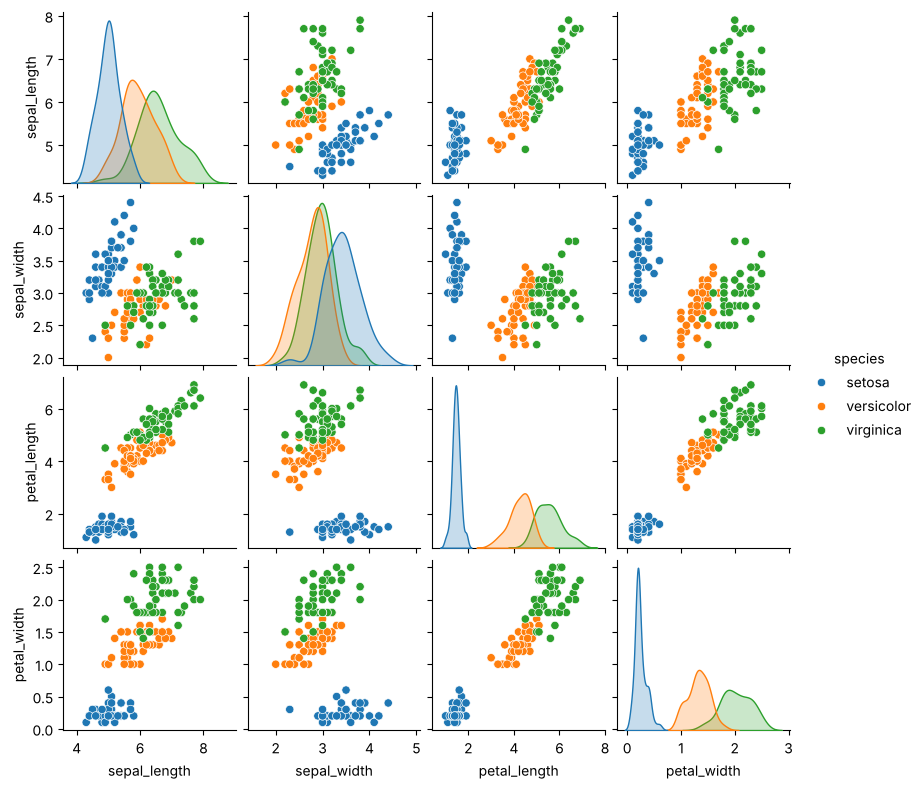

In [8]:
sns.pairplot(iris, hue='species', height=2)
plt.show()

## 7. Preprocess the data: encode labels, split and standardize
- The target `species` is converted to integer labels and then **one-hot encoded** (one output neuron per class).
- Features are **standardized** (mean 0, std 1) so that gradient descent converges faster.

In [9]:
classes = sorted(iris['species'].unique())
X_iris = iris.drop(columns='species').values
y_iris = iris['species'].map({c: i for i, c in enumerate(classes)}).values

X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Y_train = np.eye(len(classes))[y_train]
Y_test = np.eye(len(classes))[y_test]

print("Classes:", dict(enumerate(classes)))
print("Training set:", X_train.shape, " Testing set:", X_test.shape)
print("One-hot example:", y_train[0], "->", Y_train[0])

Classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
Training set: (120, 4)  Testing set: (30, 4)
One-hot example: 0 -> [1. 0. 0.]


## 8. Train the network on the Iris dataset
Architecture: **4 input neurons → 8 hidden neurons → 3 output neurons**

In [10]:
iris_net = NeuralNetwork(n_input=4, n_hidden=8, n_output=3, learning_rate=0.5)
_ = iris_net.train(X_train, Y_train, epochs=1000, X_val=X_test, Y_val=Y_test, verbose_every=200)

Epoch   200 | loss = 0.1487 | accuracy = 0.9583
Epoch   400 | loss = 0.0800 | accuracy = 0.9750
Epoch   600 | loss = 0.0626 | accuracy = 0.9750
Epoch   800 | loss = 0.0550 | accuracy = 0.9750
Epoch  1000 | loss = 0.0508 | accuracy = 0.9750


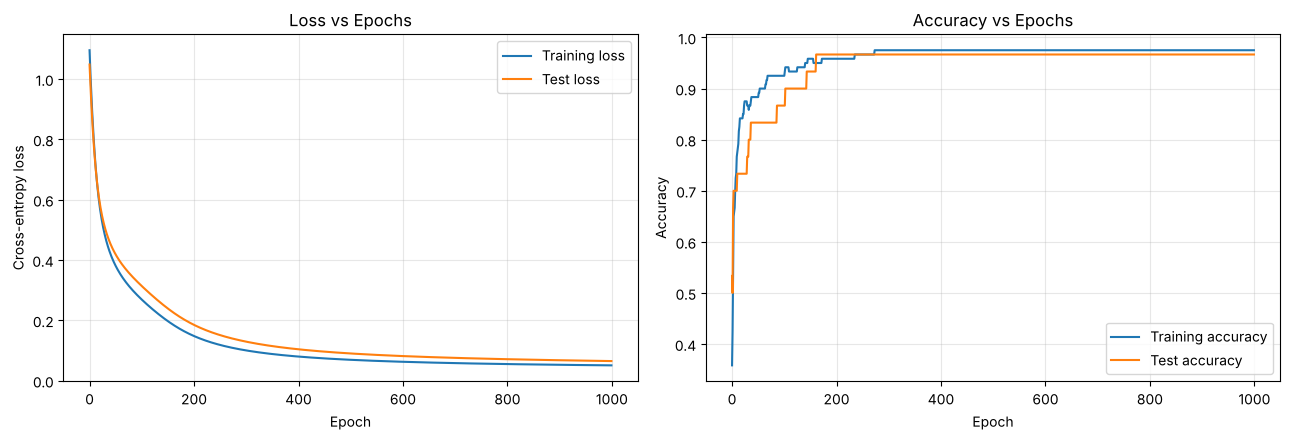

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(iris_net.history['loss'], label='Training loss')
axes[0].plot(iris_net.history['val_loss'], label='Test loss')
axes[0].set_title('Loss vs Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(iris_net.history['acc'], label='Training accuracy')
axes[1].plot(iris_net.history['val_acc'], label='Test accuracy')
axes[1].set_title('Accuracy vs Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Evaluate the network on the test set

Training accuracy: 0.975
Test accuracy    : 0.9667

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



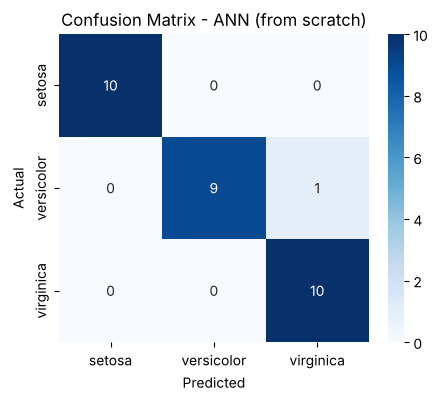

In [12]:
y_pred = iris_net.predict(X_test)
print("Training accuracy:", round(accuracy_score(y_train, iris_net.predict(X_train)), 4))
print("Test accuracy    :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=classes))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ANN (from scratch)')
plt.show()

## 10. Effect of the number of hidden neurons and the learning rate

In [13]:
rows = []
for n_hidden in [2, 4, 8, 16]:
    for lr in [0.01, 0.1, 0.5]:
        net = NeuralNetwork(4, n_hidden, 3, learning_rate=lr).train(X_train, Y_train, epochs=1000)
        rows.append({'Hidden neurons': n_hidden, 'Learning rate': lr,
                     'Final training loss': round(net.history['loss'][-1], 4),
                     'Test accuracy': round(accuracy_score(y_test, net.predict(X_test)), 4)})
tuning = pd.DataFrame(rows)
display(tuning.pivot(index='Hidden neurons', columns='Learning rate', values='Test accuracy'))

Learning rate,0.01,0.10,0.50
Hidden neurons,,,
2,0.6667,0.9333,1.0000
4,0.8000,0.9667,1.0000
8,0.7333,0.9667,0.9667
16,0.8333,0.9667,0.9667


**Interpretation:** A very small learning rate (0.01) converges too slowly in 1000 epochs, so accuracy is low. With a suitable learning rate (0.1–0.5) even a small hidden layer reaches high accuracy on Iris.

## 11. Compare with scikit-learn's MLPClassifier

In [14]:
mlp = MLPClassifier(hidden_layer_sizes=(8,), activation='logistic', solver='sgd',
                    learning_rate_init=0.5, max_iter=1000, random_state=42)
mlp.fit(X_train, y_train)

display(pd.DataFrame({
    'Model': ['ANN from scratch (NumPy)', 'scikit-learn MLPClassifier'],
    'Training accuracy': [accuracy_score(y_train, iris_net.predict(X_train)), mlp.score(X_train, y_train)],
    'Test accuracy': [accuracy_score(y_test, y_pred), mlp.score(X_test, y_test)],
}).round(4))

,Model,Training accuracy,Test accuracy
0,ANN from scratch (NumPy),0.9750,0.9667
1,scikit-learn MLPClassifier,0.9833,0.9667


## 12. Predict the species of new flowers

In [15]:
new_flowers = pd.DataFrame([[5.0, 3.4, 1.5, 0.2], [6.0, 2.8, 4.5, 1.4], [7.2, 3.0, 6.0, 2.2]],
                           columns=iris.columns[:-1])
probs = iris_net.predict_proba(scaler.transform(new_flowers.values))
result = new_flowers.copy()
result['Predicted species'] = [classes[i] for i in probs.argmax(1)]
result['Confidence'] = probs.max(1).round(4)
display(result)

,sepal_length,sepal_width,petal_length,petal_width,Predicted species,Confidence
0,5.0,3.4,1.5,0.2,setosa,0.9961
1,6.0,2.8,4.5,1.4,versicolor,0.9848
2,7.2,3.0,6.0,2.2,virginica,0.9978


## 13. Documentation summary
1. Implemented activation functions (sigmoid, tanh, ReLU, softmax) and their derivatives
2. Built a feed-forward neural network class from scratch with forward propagation, backpropagation and gradient descent
3. Verified the backpropagation gradients using numerical gradient checking
4. Trained the network on the XOR problem and visualized the non-linear decision regions
5. Loaded and preprocessed the Iris dataset (label encoding, one-hot encoding, standardization, train-test split)
6. Trained the network on Iris and plotted loss and accuracy curves
7. Evaluated the model with accuracy, a confusion matrix and a classification report
8. Studied the effect of the number of hidden neurons and the learning rate
9. Compared the results with scikit-learn's `MLPClassifier`
10. Predicted the species of new flowers

**Result:** An artificial neural network was built using the backpropagation algorithm. It solved the XOR problem and classified the Iris test set with high accuracy.